# Thanks for Nothing: executable companion
This small, seeded run explains the package API. The canonical manuscript uses the complete GNN-declared design. These are finite synthetic models, not human participants or evidence of gratitude efficacy. Original notebooks remain unchanged in `data/sources`.
We distinguish an observed absence, missing evidence, counterfactual valuation, and the enacted practice of making a restriction examinable. Gratitude for the conditions of inquiry can orient practice toward realizing emptiness; a finite predictor does not measure that realization.

In [1]:
import sys
from thanks_for_nothing.notebooks import notebook_context
context = notebook_context()
from importlib.metadata import version
from dataclasses import asdict
from thanks_for_nothing.experiments import run_study
from thanks_for_nothing.statistics import build_statistical_report
from thanks_for_nothing.nothingness import build_nothingness_audit
print({name: version(name) for name in ('thanks-for-nothing', 'generalized-notation-notation', 'realizing-emptiness')})
print('Interpreter:', sys.executable)

{'thanks-for-nothing': '0.11.0', 'generalized-notation-notation': '4.1.0', 'realizing-emptiness': '3.0.0'}
Interpreter: /Volumes/GitVault/Local/environments/tfn-release-20261022-311/bin/python


In [2]:
from thanks_for_nothing.analysis_design import load_analysis
analysis = load_analysis(context.specifications)
study = run_study(replicates=analysis.notebook_replicates, specification_dir=context.specifications)
print('Independent agents:', len({row.paired_id for row in study.rows}), 'paired rows:', len(study.rows))
print('Design controls:', study.controls)
assert all(study.controls.values())
report = build_statistical_report(study.rows, seed=study.design.seed + analysis.statistics_seed_offset, bootstrap_draws=analysis.notebook_draws, permutation_draws=analysis.notebook_draws, analysis=analysis)
for row in report.contrasts:
    print(row.endpoint, row.first, 'minus', row.second, round(row.estimate.mean_difference, 5), f'{100 * row.estimate.confidence:g}% interval', (round(row.estimate.ci95_low, 5), round(row.estimate.ci95_high, 5)))

Independent agents: 40 paired rows: 160
Design controls: {'identical_exposures': True, 'identical_baselines': True, 'absence_belief_null': True, 'dose_matched': True}
optimism_change positive_recall minus no_recall -0.00231 95% interval (-0.0024, -0.00223)
optimism_change matched_random_recall minus no_recall -5e-05 95% interval (-0.00016, 7e-05)
optimism_change absence_appreciation minus no_recall 0.0 95% interval (0.0, 0.0)
optimism_change positive_recall minus matched_random_recall -0.00226 95% interval (-0.00241, -0.00209)
brier_change positive_recall minus no_recall 0.00041 95% interval (5e-05, 0.00076)
brier_change matched_random_recall minus no_recall 0.00267 95% interval (0.00226, 0.00306)
brier_change absence_appreciation minus no_recall 0.0 95% interval (0.0, 0.0)
brier_change positive_recall minus matched_random_recall -0.00227 95% interval (-0.00276, -0.00174)


Brier and observation log loss are predictive losses: lower is better. Brier alone does not isolate calibration from resolution. Bootstrap resampling preserves independent paired units inside fixed worlds. The primary family is unchanged; subgroup summaries and NLL are exploratory.
Studentized intervals use each bootstrap sample's own variance. Unavailable intervals retain a reason and count; they never borrow another method. The exact absence null is imposed by the mechanism.

## World weighting and interval availability
Changing world weights changes the target. The convex and leave-one-world-out ranges below hold estimated world means fixed; they are not confidence intervals or additional observations. This small notebook is illustrative and does not replace the full GNN-declared experiment.

In [3]:
for summary in report.heterogeneity.weighting:
    print(summary.endpoint, summary.first, 'minus', summary.second)
    print('Equal-grid mean:', summary.equal_grid.mean)
    print('World-weight envelope:', (summary.convex_min, summary.convex_max))
    print('Leave-one-world-out:', (summary.leave_one_out_min, summary.leave_one_out_max))
for row in report.contrasts:
    print(row.endpoint, row.first, 'studentized:', asdict(row.estimate.studentized))

brier_change positive_recall minus no_recall
Equal-grid mean: 0.00040700478516545385
World-weight envelope: (-0.012350824657491467, 0.011043925197709713)
Leave-one-world-out: (-0.002252225317970611, 0.003596462145829684)
brier_change positive_recall minus matched_random_recall
Equal-grid mean: -0.002267810360343246
World-weight envelope: (-0.016077670316455517, 0.006125493294387354)
Leave-one-world-out: (-0.004366136274025896, 0.0011846546286848215)
nll_change positive_recall minus no_recall
Equal-grid mean: 0.003612915832331542
World-weight envelope: (-0.0011102231596890333, 0.01078539675626497)
Leave-one-world-out: (0.0018197956013481856, 0.004793700580336686)
nll_change positive_recall minus matched_random_recall
Equal-grid mean: 0.003063720233122677
World-weight envelope: (-0.0024662480155017152, 0.010008394706742862)
Leave-one-world-out: (0.0013275516147176307, 0.004446212295278775)
optimism_change positive_recall minus no_recall
Equal-grid mean: -0.002311059937765668
World-weight

In [4]:
absence = build_nothingness_audit(specification_dir=context.specifications)
print('Prior:', absence.prior)
print('Missing evidence:', absence.missing_posterior, 'KL bits:', absence.missing_kl_bits)
print('Observed absence:', absence.observed_absence_posterior, 'KL bits:', absence.observed_absence_kl_bits)
print('Controls:', absence.controls)
assert absence.all_controls_pass
assert absence.prior == absence.missing_posterior

Prior: (0.6, 0.4)
Missing evidence: (0.6, 0.4) KL bits: 0.0
Observed absence: (0.8709677419354838, 0.12903225806451613) KL bits: 0.2576664631760494
Controls: {'missing_preserves_prior': True, 'observed_absence_informative': True, 'uninformative_no_shift': True, 'zero_reference_no_value': True, 'zero_cost_no_value': True, 'label_permutation_invariant': True, 'invalid_probability_rejected': True, 'imported_blackwell_controls': True}


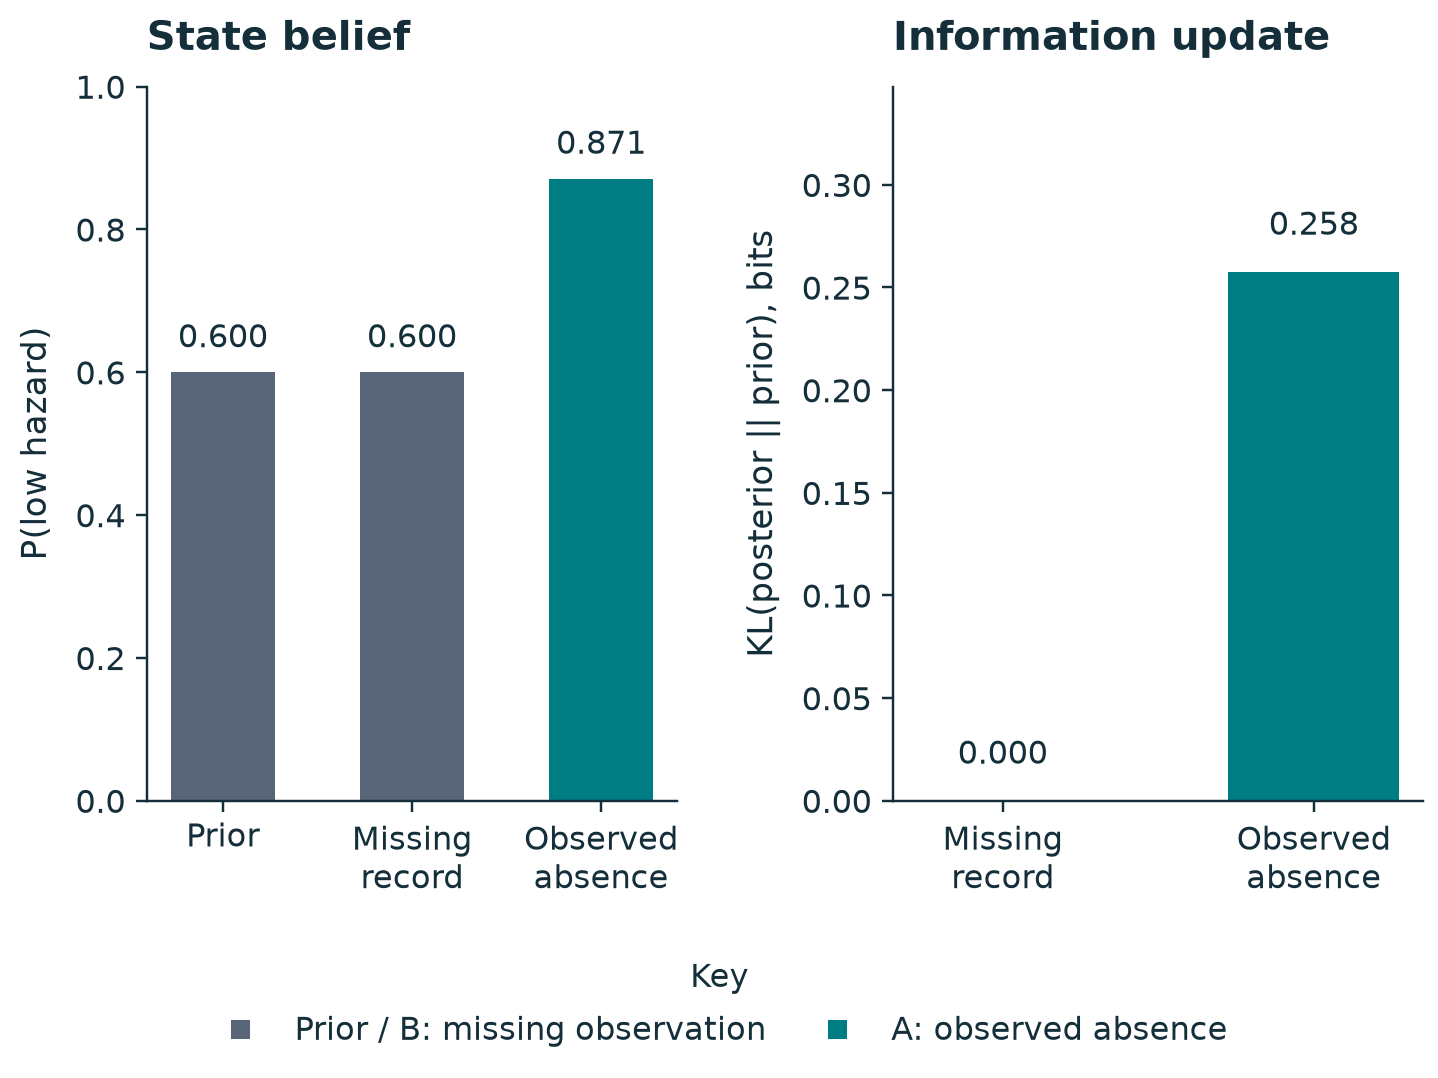

A finite absence observation updates belief; missingness preserves the prior by convention.


In [5]:
from tempfile import TemporaryDirectory
from pathlib import Path
from IPython.display import Image, display
from thanks_for_nothing.figures import absence_information
from thanks_for_nothing.concepts import CONCEPTS
with TemporaryDirectory(prefix='tfn-notebook-') as directory:
    destination = Path(directory)
    from thanks_for_nothing.artifacts import write_record
    write_record(destination / 'data/nothingness.json', absence)
    write_record(destination / 'data/concepts.json', CONCEPTS)
    figure = absence_information(absence, destination / 'figures')
    display(Image(filename=str(destination / 'figures/absence_information.png'), alt=figure.alt))
    print(figure.alt)

## From appreciation to enacted inquiry
The separate GNN practice model distinguishes preference for examinability, costly action, actual access, evidence-based retention/revision and independent prediction. Upstream Realizing Emptiness provides real QRF and finite VFE APIs. Its practice deltas are metadata; its ongoing-revision diagnostic is in-sample. This project adds the enacted policy and separate assessment stream.
The small demonstration cohort is explicit in the executable cell below. The canonical cohort comes from the packaged GNN declaration and is reported by the manuscript's generated variable ledger, rather than duplicated here. Windows are repeated observations within a replicate. Sham and no-access can incur costs while forecasts stay rigid. No-preference retains stochastic instrumental inquiry.

In [6]:
from thanks_for_nothing.emptiness_practice import build_practice_audit
from thanks_for_nothing.upstream_practice import build_upstream_practice_audit
practice = build_practice_audit(replicates=analysis.notebook_replicates, specification_dir=context.specifications)
upstream = build_upstream_practice_audit()
assert practice.all_controls_pass and upstream.all_controls_pass
print('Declared practice controls:', practice.controls)
print('Imported practice vocabulary:', upstream.protocol_ids)
print('Upstream diagnostic held out:', upstream.revision_assessment_held_out)
for contrast in practice.contrasts:
    estimate = contrast.heldout_loss_difference
    print(contrast.context, contrast.condition, 'activity/access:', contrast.mean_practice_rate, contrast.mean_access_rate, 'cost:', contrast.mean_cost)
    print('Held-out loss minus rigid:', estimate.mean, f'pointwise analytic {100 * estimate.confidence:g}%:', (estimate.analytic_low, estimate.analytic_high))

Declared practice controls: {'exact_vfe_matches_evidence_sum': True, 'useful_prior_retained': True, 'contradicted_prior_revisable': True, 'equal_likelihood_tie_retains_prior': True, 'invalid_channel_rejected': True, 'paired_exposures': True, 'no_access_preserves_forecasts': True, 'sham_preserves_forecasts': True, 'policy_uses_previous_observed_gain_only': True, 'candidate_permutation_invariant': True, 'preference_changes_initial_policy': True}
Imported practice vocabulary: ('attentional_opacification', 'dependent_origination_inquiry', 'compassion_alignment')
Upstream diagnostic held out: False
stationary inquiry activity/access: 0.78125 0.78125 cost: 0.15624999999999997
Held-out loss minus rigid: 0.0 pointwise analytic 95%: (0.0, 0.0)
stationary no_preference activity/access: 0.19791666666666666 0.19791666666666666 cost: 0.03958333333333333
Held-out loss minus rigid: 0.0 pointwise analytic 95%: (0.0, 0.0)
stationary sham activity/access: 0.78125 0.0 cost: 0.15624999999999997
Held-out l

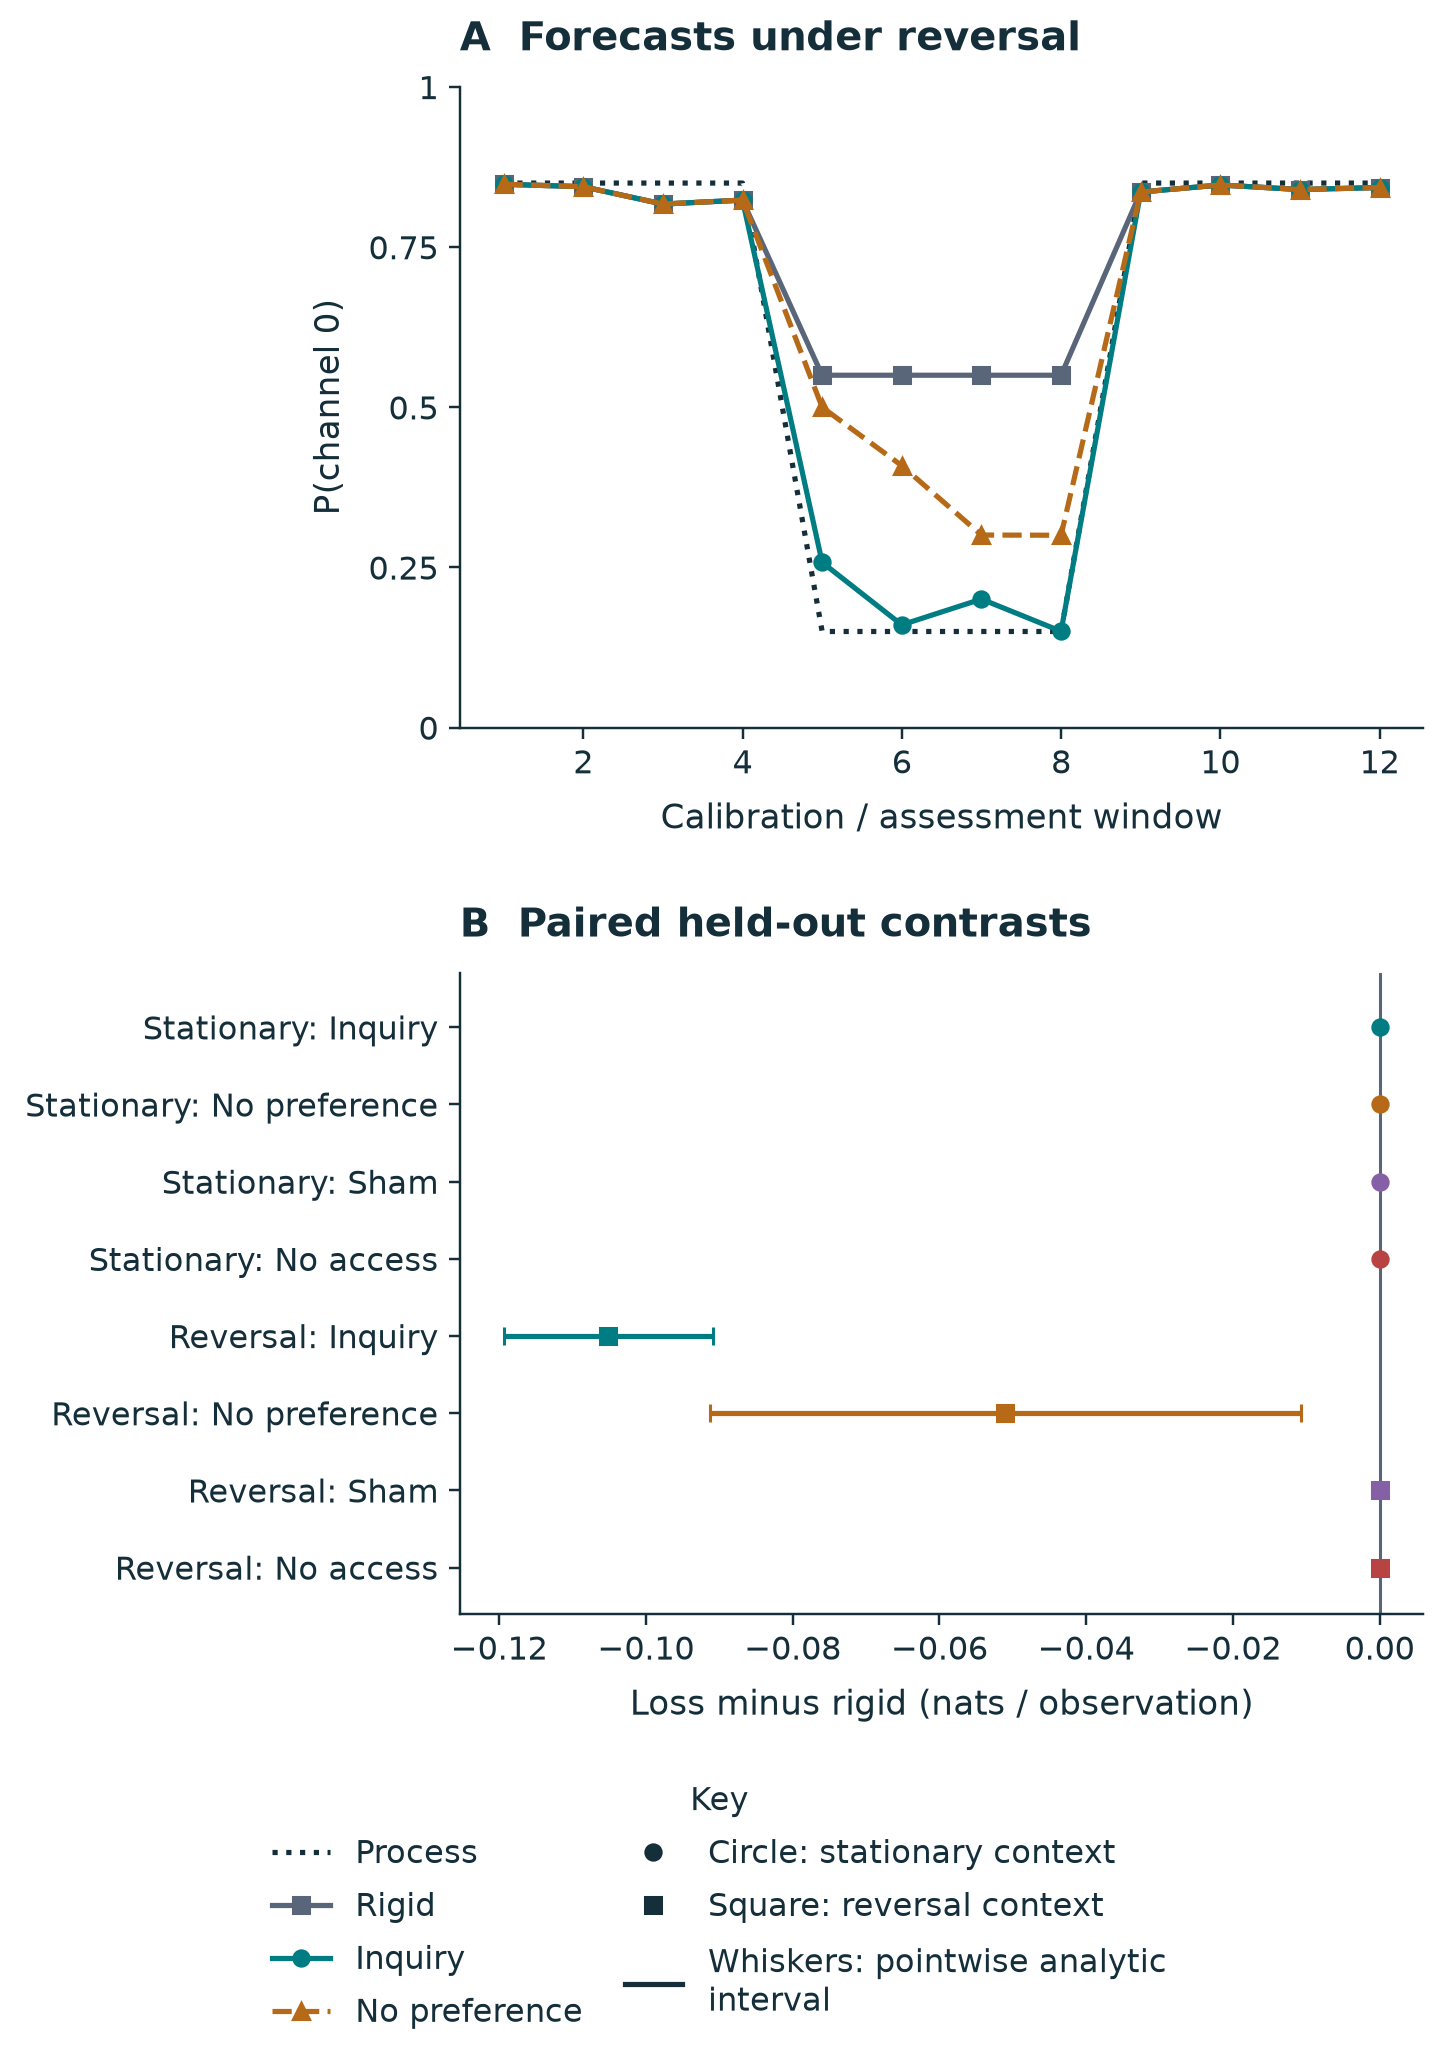

Reversal forecasts and paired intervals; sham and no-access forecasts retain exact nulls.


In [7]:
from thanks_for_nothing.practice_figures import practice_revision
with TemporaryDirectory(prefix='tfn-practice-notebook-') as directory:
    destination = Path(directory)
    write_record(destination / 'data/emptiness_practice.json', practice)
    record = practice_revision(practice, destination / 'figures')
    display(Image(filename=str(destination / 'figures/practice_revision.png'), alt=record.alt))
    print(record.alt)

## Exhaustive decisions are conditional, not policy averages
Every possible calibration count is checked against a rational evidence oracle. Binomial count masses give exact selection probabilities under the declared process. Logarithms and losses remain numerical evaluations. This calculation is conditional on an effective inquiry; it does not integrate access, previous gains, activity costs or the repeated policy. A stationary seeded zero does not prove a zero selection probability. Neither this oracle nor deterministic replay establishes human parameter recovery.


In [8]:
from thanks_for_nothing.practice_exact import build_exact_decision_audit
exact = build_exact_decision_audit(specification_dir=context.specifications)
assert exact.all_controls_pass
print('Open-family counts:', [row.zero_count for row in exact.rows if row.supports_open])
for point in exact.operating_points:
    print('Process p:', point.process_probability)
    print('P(open | effective inquiry):', format(point.open_probability, '.9g'))
    print('Conditional expected loss minus restricted:', format(point.expected_loss_difference, '+.9g'))
    print('Exact probability ratio:', point.open_probability_numerator, '/', point.open_probability_denominator)
print('All count masses sum to one:', all(p.probability_total_exact for p in exact.operating_points))

Open-family counts: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Process p: 0.15
P(open | effective inquiry): 0.994126513
Conditional expected loss minus restricted: -0.341492404
Exact probability ratio: 8339337623889579439784984154917 / 8388608000000000000000000000000
Process p: 0.85
P(open | effective inquiry): 1.43362441e-08
Conditional expected loss minus restricted: +4.59820882e-09
Exact probability ratio: 120261132232793102382597 / 8388608000000000000000000000000
All count masses sum to one: True


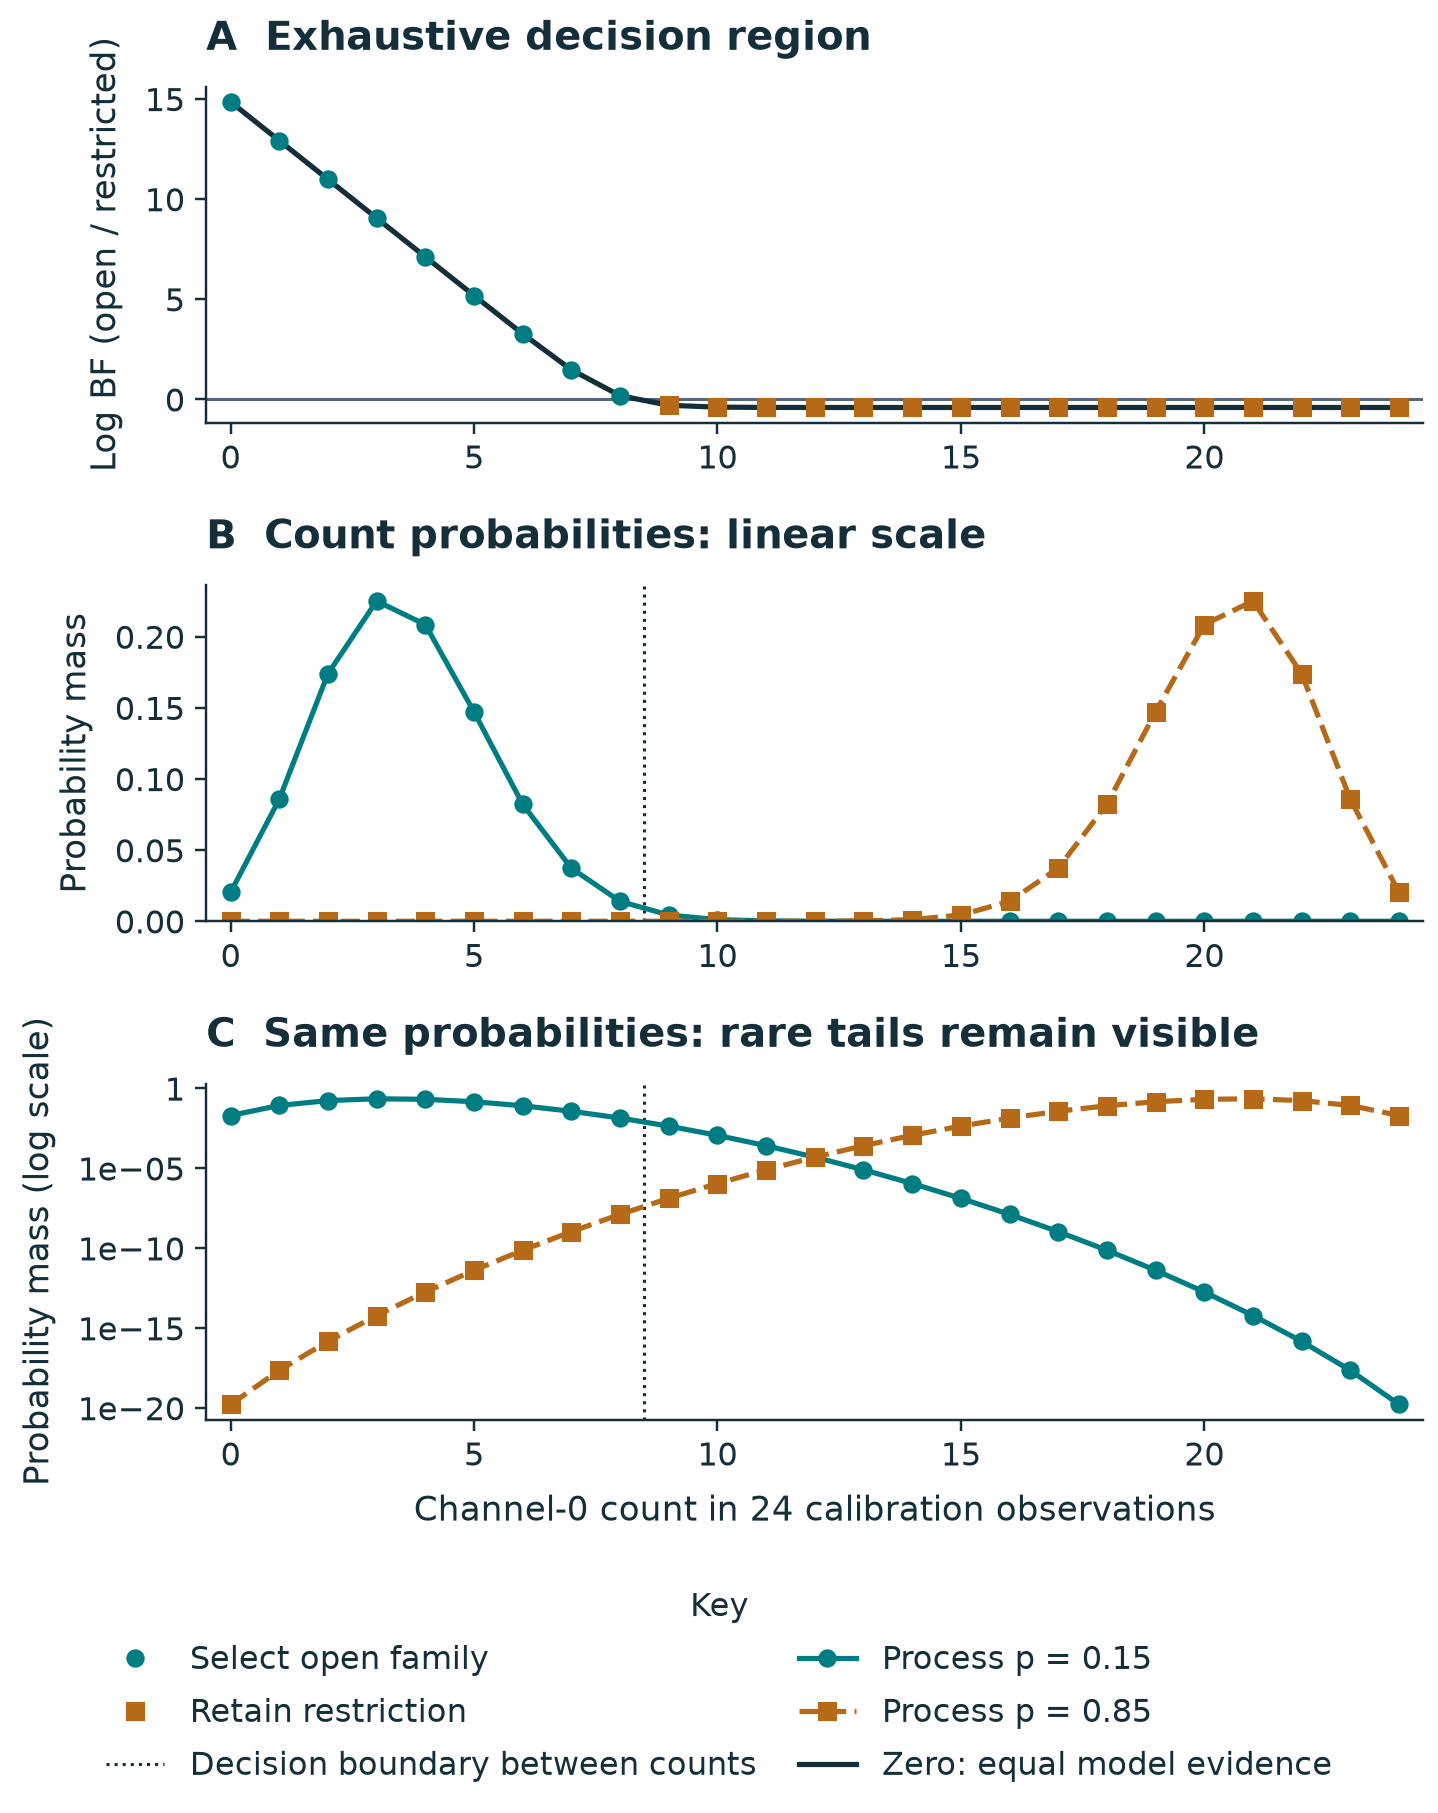

Linear and log count masses show rare tails; dotted boundaries separate family decisions.


In [9]:
from thanks_for_nothing.practice_figures import exact_decision
with TemporaryDirectory(prefix='tfn-exact-notebook-') as directory:
    destination = Path(directory)
    write_record(destination / 'data/exact_decision.json', exact)
    record = exact_decision(exact, destination / 'figures')
    display(Image(filename=str(destination / 'figures/exact_decision.png'), alt=record.alt))
    print(record.alt)

## What the inquiry choices can identify

Conditional on the same previous-gain history, the logistic policy identifies
only `action_precision * (preference - cost)` and
`action_precision * previous_gain_weight`. A shared value/cost shift and a
compensating scale transformation preserve all its choice probabilities.
The example checks this algebra against the actual policy API. It does not
claim that observed activity costs or human gratitude are thereby identified.


In [10]:
import numpy as np
from thanks_for_nothing.practice_inference import practice_probability
design = practice.design
scale, shift = 2.0, 0.3
transformed = design.model_copy(update={
    'action_precision': design.action_precision / scale,
    'examinability_preference': scale * design.examinability_preference + shift,
    'practice_cost': scale * design.practice_cost + shift,
    'previous_gain_weight': scale * design.previous_gain_weight,
})
for gain in (0.0, 0.03, 0.7, 2.0):
    original = practice_probability(design, design.examinability_preference, gain)
    equivalent = practice_probability(transformed, transformed.examinability_preference, gain)
    assert np.isclose(original, equivalent, atol=1e-14, rtol=0)
    print('Previous gain:', gain, 'original / equivalent:', original, equivalent)


Previous gain: 0.0 original / equivalent: 0.7685247834990178 0.7685247834990178
Previous gain: 0.03 original / equivalent: 0.7989910002494707 0.7989910002494707
Previous gain: 0.7 original / equivalent: 0.9955037268390589 0.9955037268390589
Previous gain: 2.0 original / equivalent: 0.9999981494022271 0.9999981494022271


## Read the mechanism without equating it with realization

The dashed appreciation-to-preference link is a human proposal. Solid arrows
are declared computational dependencies. The current evidence distinguishes
activity, access, retention/revision and prediction, while future experiments
must separate appreciation from patience, anticipation and compliance.


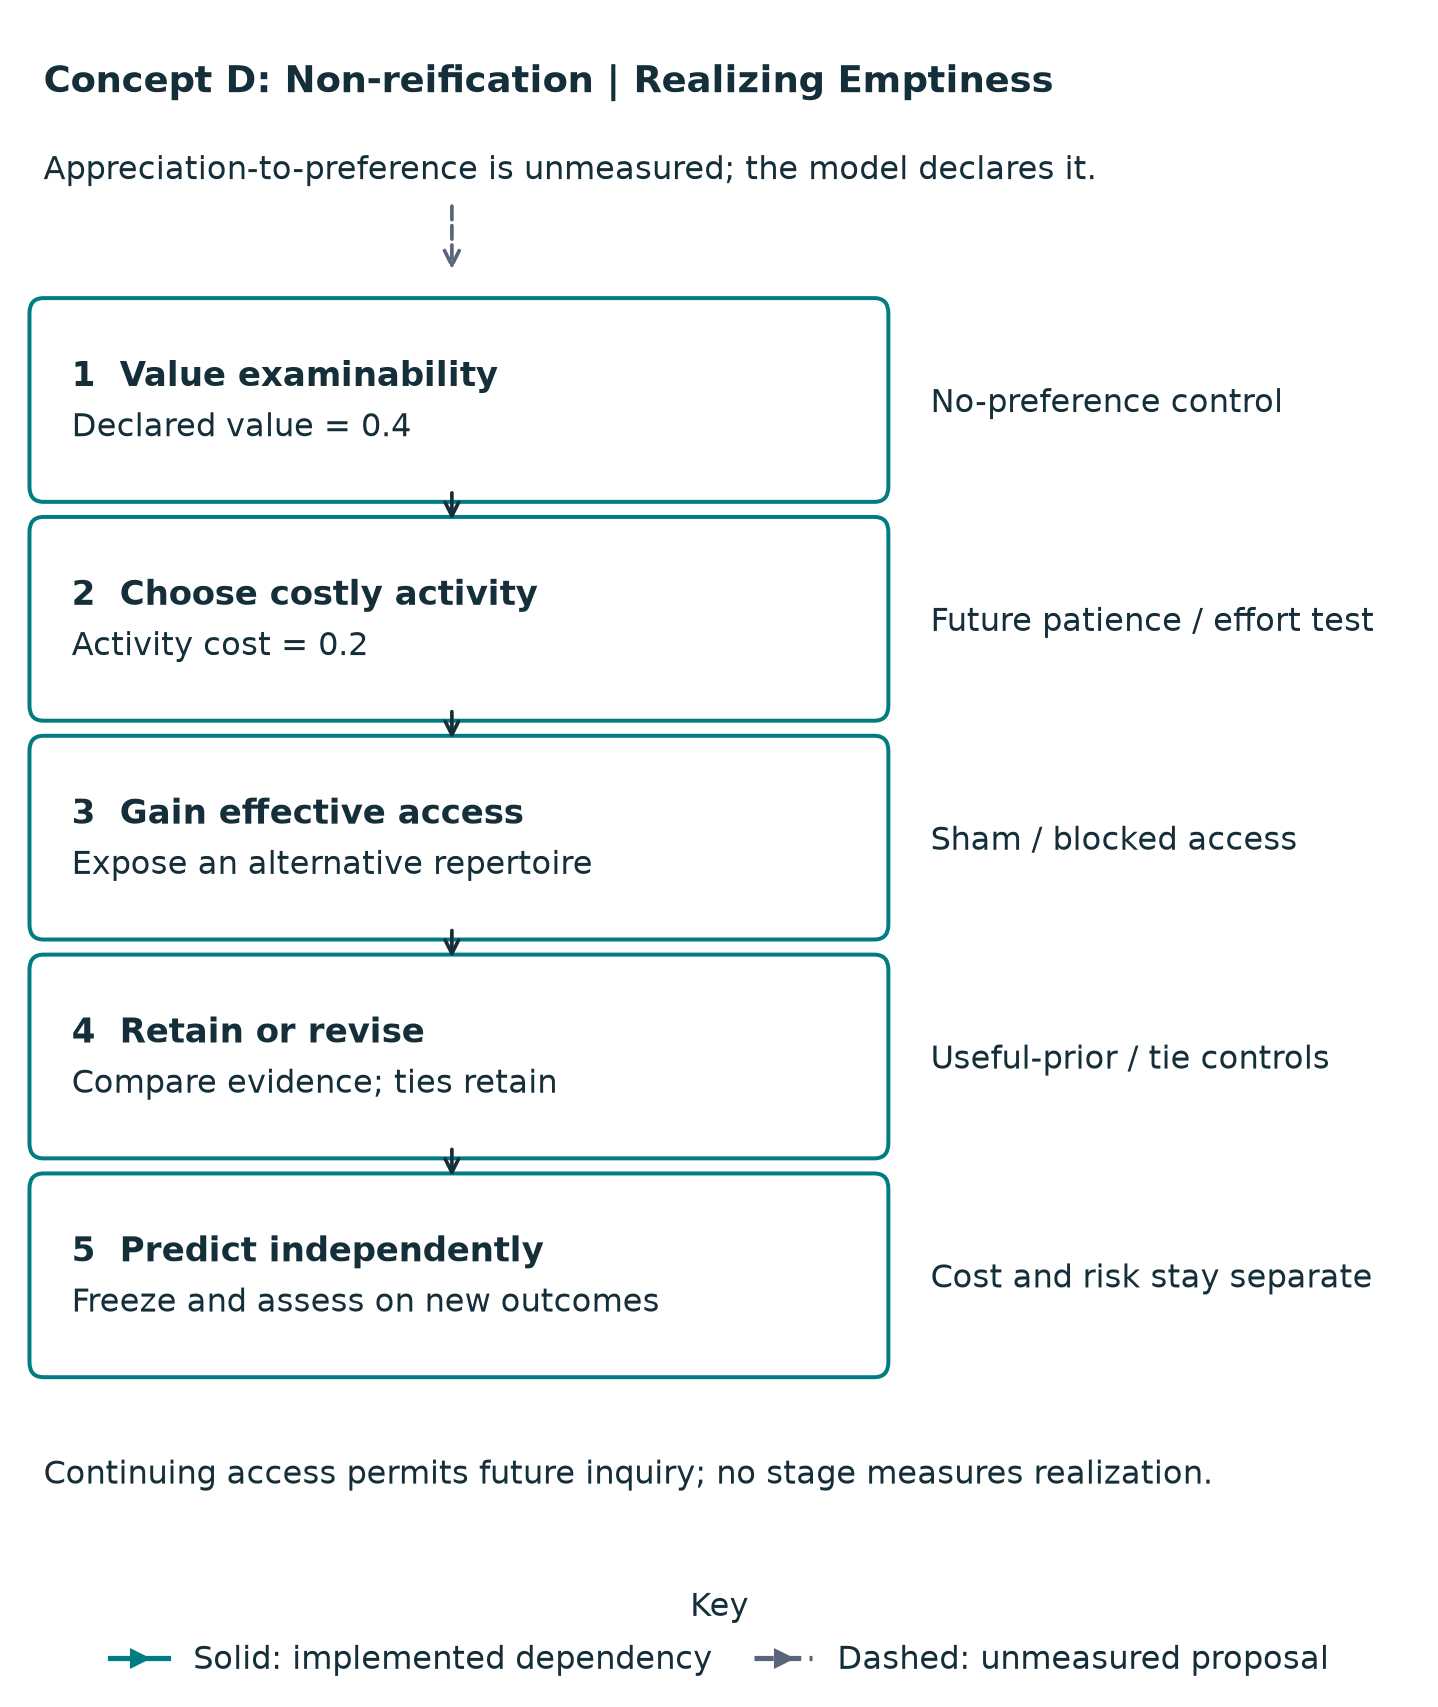

A dashed unmeasured human link leads to five declared finite-model stages and their controls.


In [11]:
from thanks_for_nothing.practice_mechanism import practice_mechanism
from thanks_for_nothing.concepts import CONCEPTS
with TemporaryDirectory(prefix='tfn-mechanism-companion-') as directory:
    destination = Path(directory)
    write_record(destination / 'data/emptiness_practice.json', practice)
    write_record(destination / 'data/upstream_practice.json', upstream)
    write_record(destination / 'data/concepts.json', CONCEPTS)
    draw = practice_mechanism(practice, destination / 'figures')
    display(Image(filename=str(destination / 'figures/practice_mechanism.png'), alt=draw.alt))
    print(draw.alt)


## Continue reading
The manuscript, scholarship guide, model contract and notebook audit explain assumptions and evidence ceilings. Fisher, Sandved Smith and Hohwy's preprint v1 provides the source theory; this project adds paired controls and explicit operational distinctions. Philosophical emptiness is not identified with any one finite variable.